In [125]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [126]:
import sys
from pathlib import Path

root = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
sys.path.append(str(root / "src"))

from notebook_cache import NotebookCache

# results and prints live on disk, so they survive kernel restarts; one folder per notebook
cache = NotebookCache(root / "cache" / "hopper")

# Stress test: DDPG vs TD3 vs SAC (and PPO) on Hopper

On Pendulum all three off-policy methods tied at about -165, and DDPG's +10 overestimation didn't hurt. This notebook moves them to a task where that bias is known to break DDPG.

**Hopper-v5** (MuJoCo): a one-legged robot in 2D that should hop forward as fast as it can without falling.

- obs: 11 numbers (joint angles, joint velocities, torso height and tilt). The x position is left out, so the policy can't depend on where it is
- action: 3 torques (thigh, leg, foot), each in `[-1, 1]`
- reward per step: `forward velocity + 1 (alive bonus) - 0.001·|a|²`
- episode ends by **termination** when the robot falls (torso too low or tilted too far), otherwise by **truncation** at 1000 steps


In [127]:
import warnings

import gymnasium as gym
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F

# MuJoCo model-file deprecation noise
warnings.filterwarnings("ignore", message=".*settotalmass.*")

device = "cuda" if torch.cuda.is_available() else "cpu"
ENV = "Hopper-v5"
env = gym.wrappers.RecordEpisodeStatistics(gym.make(ENV))
obs_dim = env.observation_space.shape[0]
act_dim = env.action_space.shape[0]
act_high = float(env.action_space.high[0])
print(f"{env.observation_space=}")
print(f"{env.action_space=}")
print(f"{obs_dim=}  {act_dim=}  {act_high=}")
print(f"max steps: {env.spec.max_episode_steps}")

env.observation_space=Box(-inf, inf, (11,), float64)
env.action_space=Box(-1.0, 1.0, (3,), float32)
obs_dim=11  act_dim=3  act_high=1.0
max steps: 1000


In [128]:
scores, lengths, n_term = [], [], 0
for i in range(20):
    env.reset(seed=i)
    done = False
    while not done:
        _, r, term, trunc, info = env.step(env.action_space.sample())
        done = term or trunc
    scores.append(float(info["episode"]["r"]))
    lengths.append(int(info["episode"]["l"]))
    n_term += term
print(
    f"random: return {np.mean(scores):.0f}, length {np.mean(lengths):.0f} steps, fell in {n_term}/20"
)
print("(good agents: about 3000+, hopping the full 1000 steps)")

random: return 13, length 19 steps, fell in 20/20
(good agents: about 3000+, hopping the full 1000 steps)


## Step 1: where the reward comes from, and why `T` matters now

The env reports the three reward terms separately in `info`. Run one random episode, add up each term, and check what ended it:

- **healthy** means torso height `z > 0.7` and tilt `|angle| < 0.2` rad (plus a sanity bound on the state). Leaving that range terminates the episode.
- `qpos[1:3]` holds the torso's height and tilt (`qpos[0]` is the x position the obs leaves out).


In [129]:
def reward_parts(policy, seed=0):
    """One episode: summed reward terms, length, and the torso's height/tilt at the end."""
    env = gym.make(ENV)
    s, _ = env.reset(seed=seed)
    parts = dict(reward_forward=0.0, reward_survive=0.0, reward_ctrl=0.0)
    done, n = False, 0
    while not done:
        s, r, term, trunc, info = env.step(policy(s))
        for k in parts:
            parts[k] += float(info[k])
        n += 1
        done = term or trunc
    z, angle = env.unwrapped.data.qpos[1:3]
    return parts, n, term, z, angle


policies = {
    "random": lambda s: env.action_space.sample(),
    "zero torque": lambda s: np.zeros(act_dim),
}
for name, pi in policies.items():
    parts, n, term, z, angle = reward_parts(pi)
    terms = "  ".join(f"{k[7:]}={v:+7.2f}" for k, v in parts.items())
    end = "fell" if term else "truncated"
    print(f"{name:12s} {n:4d} steps ({end}, z={z:.2f}, angle={angle:+.2f})   {terms}")

random         17 steps (fell, z=1.23, angle=-0.20)   forward=  -9.09  survive= +16.00  ctrl=  -0.02
zero torque   141 steps (fell, z=1.20, angle=-0.20)   forward=  -8.83  survive=+140.00  ctrl=  +0.00


**The alive bonus dominates early.** A random policy's return is almost entirely `survive` (+1 per step). Forward progress is a rounding error, and slightly negative here. Doing nothing (zero torque) actually lasts longer than flailing, 141 steps vs 16, but it still tips over. So just staying upright is a skill the agent has to learn, before any hopping.

**"Falling" is strict.** Both runs ended with the torso still high (`z=1.20`) but tilted past the 0.2 rad (about 11°) limit. Leaning too far counts as a fall.

**This is the first env where `T` actually fires.** On Pendulum `T` was always 0. Here, falling sets `T=1` and the target becomes `y = r`, with no future. Two ways to get it wrong:

- **Bootstrapping through a fall** (treating `term` like `trunc`): the critic would believe a fallen robot keeps collecting about +1 per step, worth up to `1/(1-γ) = 100`. Falling would look almost free, which removes the main thing the agent needs to learn.
- **Zeroing at the 1000-step cut** (treating `trunc` like `term`): a perfectly healthy hopper at step 999 would look like it has no future. Its value is inconsistent with the identical state at step 10.

The buffer from the last notebook already stores only `term`, so it gets this right without changes.


## Step 2: bring the agents over, and time them

The buffer, the networks, `soft_update`, `DDPG`, `TD3` and `SAC` are **copied unchanged** from `ddpg_td3_sac.ipynb`. They were already written for any `obs_dim`, `act_dim` and `act_high`, and those globals now hold Hopper's numbers (11, 3, 1.0). The only thing that had to work differently is `T`, and the buffer already stores only `term` (Step 1).


In [130]:
class ReplayBuffer:
    def __init__(self, size=100_000):
        self.S = np.zeros((size, obs_dim), np.float32)
        self.A = np.zeros((size, act_dim), np.float32)
        self.R = np.zeros(size, np.float32)
        self.S2 = np.zeros((size, obs_dim), np.float32)
        self.T = np.zeros(size, np.float32)
        self.size, self.i, self.n = size, 0, 0  # i: next slot to write, n: slots filled

    def add(self, s, a, r, s2, term):
        self.S[self.i], self.A[self.i], self.R[self.i] = s, a, r
        self.S2[self.i], self.T[self.i] = s2, term
        self.i = (self.i + 1) % self.size  # wrap around: overwrite the oldest
        self.n = min(self.n + 1, self.size)

    def sample(self, batch_size=256):
        idx = np.random.randint(0, self.n, batch_size)
        f = lambda x: torch.as_tensor(x[idx], device=device)
        return dict(S=f(self.S), A=f(self.A), R=f(self.R), S2=f(self.S2), T=f(self.T))

In [131]:
def mlp(inp, out, hidden=256):
    return nn.Sequential(
        nn.Linear(inp, hidden), nn.ReLU(),
        nn.Linear(hidden, hidden),
        nn.ReLU(), nn.Linear(hidden, out),
    ).to(device)


class Actor(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = mlp(obs_dim, act_dim)

    def forward(self, s):
        return act_high * torch.tanh(self.net(s))  # squash into the valid torque range


class Critic(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = mlp(obs_dim + act_dim, 1)  # action goes in, one Q comes out

    def forward(self, s, a):
        return self.net(torch.cat([s, a], -1)).squeeze(-1)

In [132]:
import copy


def soft_update(target, net, tau=0.005):
    with torch.no_grad():
        for tp, p in zip(target.parameters(), net.parameters()):
            tp.lerp_(p, tau)  # tp += tau * (p - tp)

In [133]:
class DDPG:
    def __init__(self, lr=1e-3, gamma=0.99, tau=0.005, expl_noise=0.1):
        self.gamma, self.tau, self.expl_noise = gamma, tau, expl_noise
        self.actor, self.critic = Actor(), Critic()
        self.actor_t, self.critic_t = (
            copy.deepcopy(self.actor),
            copy.deepcopy(self.critic),
        )
        self.opt_a = torch.optim.Adam(self.actor.parameters(), lr=lr)
        self.opt_c = torch.optim.Adam(self.critic.parameters(), lr=lr)

    def act(self, s, explore=True):
        with torch.no_grad():
            a = self.actor(torch.as_tensor(s, dtype=torch.float32, device=device)).cpu().numpy()
        if explore:
            a = a + np.random.normal(0, self.expl_noise * act_high, act_dim)  # the only exploration
        return np.clip(a, -act_high, act_high)

    def update(self, b):
        with torch.no_grad():
            q2 = self.critic_t(b["S2"], self.actor_t(b["S2"]))  # actor stands in for max_a
            y = b["R"] + self.gamma * (1 - b["T"]) * q2
        q = self.critic(b["S"], b["A"])
        critic_loss = F.mse_loss(q, y)
        self.opt_c.zero_grad()
        critic_loss.backward()
        self.opt_c.step()

        actor_loss = -self.critic(b["S"], self.actor(b["S"])).mean()  # push mu(s) up the Q surface
        self.opt_a.zero_grad()
        actor_loss.backward()
        self.opt_a.step()

        soft_update(self.actor_t, self.actor, self.tau)
        soft_update(self.critic_t, self.critic, self.tau)
        return dict(critic_loss=critic_loss.item(), q=q.mean().item())

In [134]:
class TD3(DDPG):
    def __init__(self, lr=1e-3, policy_delay=2, target_noise=0.2, noise_clip=0.5, **kw):
        super().__init__(lr=lr, **kw)
        self.policy_delay, self.target_noise, self.noise_clip = (
            policy_delay,
            target_noise,
            noise_clip,
        )
        self.critic2 = Critic()
        self.critic2_t = copy.deepcopy(self.critic2)
        self.opt_c = torch.optim.Adam(
            [*self.critic.parameters(), *self.critic2.parameters()], lr=lr
        )
        self.n_updates = 0

    def update(self, b):
        with torch.no_grad():
            # fix 3: smooth the target, jitter mu_t(s') so Q can't rely on one sharp peak
            noise = (torch.randn_like(b["A"]) * self.target_noise * act_high).clamp(
                -self.noise_clip * act_high, self.noise_clip * act_high
            )
            a2 = (self.actor_t(b["S2"]) + noise).clamp(-act_high, act_high)
            # fix 1: two critics, trust the smaller target
            q2 = torch.min(self.critic_t(b["S2"], a2), self.critic2_t(b["S2"], a2))
            y = b["R"] + self.gamma * (1 - b["T"]) * q2
        q = self.critic(b["S"], b["A"])
        critic_loss = F.mse_loss(q, y) + F.mse_loss(self.critic2(b["S"], b["A"]), y)
        self.opt_c.zero_grad()
        critic_loss.backward()
        self.opt_c.step()

        # fix 2: update the actor (and all targets) only every policy_delay critic updates
        self.n_updates += 1
        if self.n_updates % self.policy_delay == 0:
            actor_loss = -self.critic(b["S"], self.actor(b["S"])).mean()
            self.opt_a.zero_grad()
            actor_loss.backward()
            self.opt_a.step()
            soft_update(self.actor_t, self.actor, self.tau)
            soft_update(self.critic_t, self.critic, self.tau)
            soft_update(self.critic2_t, self.critic2, self.tau)
        return dict(critic_loss=critic_loss.item(), q=q.mean().item())

In [135]:
class GaussianActor(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = mlp(obs_dim, 2 * act_dim)  # mean and log-std per action dim

    def forward(self, s, deterministic=False):
        """Returns (action in [-2, 2], log-prob of that action)."""
        mu, log_std = self.net(s).chunk(2, -1)
        log_std = log_std.clamp(-20, 2)  # keep std in a sane range
        dist = torch.distributions.Normal(mu, log_std.exp())
        u = mu if deterministic else dist.rsample()  # rsample: the sample stays differentiable
        a = torch.tanh(u)  # squash into [-1, 1]
        # change of variables: tanh squeezes density near +-1, so correct by log(1 - tanh(u)^2),
        # written in a numerically stable form
        logp = dist.log_prob(u).sum(-1) - (2 * (np.log(2) - u - F.softplus(-2 * u))).sum(-1)
        return act_high * a, logp

In [136]:
class SAC:
    def __init__(self, lr=1e-3, gamma=0.99, tau=0.005, alpha=None):
        self.gamma, self.tau = gamma, tau
        self.actor = GaussianActor()
        self.critic, self.critic2 = Critic(), Critic()
        self.critic_t, self.critic2_t = (
            copy.deepcopy(self.critic),
            copy.deepcopy(self.critic2),
        )
        self.opt_a = torch.optim.Adam(self.actor.parameters(), lr=lr)
        self.opt_c = torch.optim.Adam(
            [*self.critic.parameters(), *self.critic2.parameters()], lr=lr
        )
        # alpha=None: learn it. Learn log(alpha) so alpha stays positive; start at alpha = 1
        self.auto_alpha = alpha is None
        self.log_alpha = torch.tensor(
            float(np.log(alpha or 1.0)), device=device, requires_grad=self.auto_alpha
        )
        self.opt_alpha = torch.optim.Adam([self.log_alpha], lr=lr)
        self.target_entropy = -act_dim  # how random to stay: about std 0.09 in [-1, 1] units

    def act(self, s, explore=True):
        with torch.no_grad():
            a, _ = self.actor(
                torch.as_tensor(s, dtype=torch.float32, device=device),
                deterministic=not explore,
            )
        return a.cpu().numpy()  # exploration comes from sampling, no added noise

    def update(self, b):
        alpha = self.log_alpha.exp().item()
        with torch.no_grad():
            a2, logp2 = self.actor(b["S2"])  # fresh sample from the current policy, no target actor
            q2 = torch.min(self.critic_t(b["S2"], a2), self.critic2_t(b["S2"], a2))
            y = b["R"] + self.gamma * (1 - b["T"]) * (
                q2 - alpha * logp2
            )  # + bonus for being random
        q = self.critic(b["S"], b["A"])
        critic_loss = F.mse_loss(q, y) + F.mse_loss(self.critic2(b["S"], b["A"]), y)
        self.opt_c.zero_grad()
        critic_loss.backward()
        self.opt_c.step()

        a, logp = self.actor(b["S"])  # gradient flows through the sampled a (rsample)
        q_pi = torch.min(self.critic(b["S"], a), self.critic2(b["S"], a))
        actor_loss = (alpha * logp - q_pi).mean()  # high Q, but stay random
        self.opt_a.zero_grad()
        actor_loss.backward()
        self.opt_a.step()

        if self.auto_alpha:
            # entropy below target -> raise alpha (reward randomness more), above -> lower it
            alpha_loss = -(self.log_alpha * (logp.detach() + self.target_entropy)).mean()
            self.opt_alpha.zero_grad()
            alpha_loss.backward()
            self.opt_alpha.step()

        soft_update(self.critic_t, self.critic, self.tau)
        soft_update(self.critic2_t, self.critic2, self.tau)
        return dict(
            critic_loss=critic_loss.item(),
            q=q.mean().item(),
            alpha=alpha,
            entropy=-logp.mean().item(),
        )

**How long will training take?** Pendulum needed 20k steps. Hopper usually needs a few hundred thousand, still with one gradient update per env step. Time a couple of thousand real steps of each agent (env step + `act` + one `update`) to see what a run will cost.

SAC should be the slowest: its update samples from the actor twice (for `s'` and `s`), and it also steps `α`.


In [137]:
import time


@cache
def steps_per_sec(algo, n=2000, **hp):
    """Env steps per second of the full off-policy loop: step, act, add, one update."""
    agent, buf = globals()[algo](**hp), ReplayBuffer(size=10_000)
    s, _ = env.reset(seed=0)
    for i in range(n + 1000):  # first 1000: random warm-up so the buffer can be sampled
        if i == 1000:
            t0 = time.time()
        a = env.action_space.sample() if i < 1000 else agent.act(s)
        s2, r, term, trunc, _ = env.step(a)
        buf.add(s, a, r, s2, term)
        s = s2 if not (term or trunc) else env.reset()[0]
        if i >= 1000:
            agent.update(
                buf.sample(256)
            )  # .item() in update waits for the GPU, so the timing is honest
    return n / (time.time() - t0)


for algo in ["DDPG", "TD3", "SAC"]:
    sps = steps_per_sec(algo)
    print(f"{algo:5s} {sps:5.0f} steps/s   300k steps = {300_000 / sps / 60:4.1f} min")

steps_per_sec: cached, 3 call(s) stored
DDPG    537 steps/s   300k steps =  9.3 min
TD3     550 steps/s   300k steps =  9.1 min
SAC     263 steps/s   300k steps = 19.0 min


## Step 3: the training loop, with greedy evaluation

Same interleaved loop as on Pendulum (one env step, one update), with three changes:

- **Longer warm-up:** 10k random steps instead of 1k. Random Hopper episodes last about 23 steps, so 10k steps is about 400 short falls, which gives a varied first buffer.
- **The buffer never overwrites:** its size is `total_steps`, so nothing is thrown away. 300k transitions of 11 floats is about 30 MB.
- **Greedy evaluation every 10k steps:** 5 episodes with no exploration noise. Training returns include the noise, and on Hopper a little noise is enough to tip the robot over, so they understate the policy. The eval curve is the one to trust.


In [138]:
def evaluate(agent, n_episodes=5, seed=100):
    """Greedy (no noise) returns."""
    env = gym.wrappers.RecordEpisodeStatistics(gym.make(ENV))
    scores = []
    for i in range(n_episodes):
        s, _ = env.reset(seed=seed + i)
        done = False
        while not done:
            s, _, term, trunc, info = env.step(agent.act(s, explore=False))
            done = term or trunc
        scores.append(float(info["episode"]["r"]))
    return np.mean(scores), np.std(scores)

In [139]:
@cache
def train(
    algo="DDPG", total_steps=300_000, start_steps=10_000, batch_size=256,
    eval_every=10_000, seed=0, **hp,
):
    torch.manual_seed(seed)
    np.random.seed(seed)
    env = gym.wrappers.RecordEpisodeStatistics(gym.make(ENV))
    env.action_space.seed(seed)
    agent = globals()[algo](**hp)  # class by name
    buf = ReplayBuffer(size=total_steps)  # big enough to never overwrite

    s, _ = env.reset(seed=seed)
    # ends[i]: env step at which episode i finished
    returns, ends, evals, log, recent = ([], [], [], [], [])
    for step in range(1, total_steps + 1):
        a = env.action_space.sample() if step <= start_steps else agent.act(s)
        s2, r, term, trunc, info = env.step(a)
        buf.add(s, a, r, s2, term)  # a fall zeroes the future, the 1000-step cut doesn't
        s = s2
        if term or trunc:
            returns.append(float(info["episode"]["r"]))
            ends.append(step)
            s, _ = env.reset()

        if step > start_steps:
            recent.append(agent.update(buf.sample(batch_size)))
        if step % eval_every == 0:
            m, sd = evaluate(agent)
            evals.append(dict(step=step, mean=m, std=sd))
            stats = {k: np.mean([st[k] for st in recent]) for k in recent[0]} if recent else {}
            log.append(dict(step=step, **stats))
            recent = []
            print(
                f"steps {step:7d}  episodes {len(returns):5d}  train avg10={np.mean(returns[-10:]):6.0f}  "
                f"greedy={m:6.0f} ± {sd:4.0f}  "
                + "  ".join(f"{k}={v:.2f}" for k, v in stats.items())
            )

    return dict(agent=agent, returns=returns, ends=ends, evals=evals, log=log)

train: cached, 3 call(s) stored


In [140]:
res_ddpg = train("DDPG")

steps   10000  episodes   428  train avg10=    19  greedy=    18 ±    0  
steps   20000  episodes   603  train avg10=   220  greedy=   216 ±    2  critic_loss=11.65  q=48.17
steps   30000  episodes   688  train avg10=   288  greedy=   273 ±   35  critic_loss=52.43  q=159.23
steps   40000  episodes   776  train avg10=   207  greedy=    46 ±   72  critic_loss=132.54  q=261.58
steps   50000  episodes   850  train avg10=   425  greedy=   600 ±   45  critic_loss=246.50  q=376.43
steps   60000  episodes   917  train avg10=   212  greedy=   195 ±   80  critic_loss=331.49  q=480.45
steps   70000  episodes  1016  train avg10=   340  greedy=   476 ±  253  critic_loss=399.62  q=534.19
steps   80000  episodes  1069  train avg10=   589  greedy=   639 ±  335  critic_loss=472.79  q=589.28
steps   90000  episodes  1110  train avg10=   775  greedy=   397 ±  155  critic_loss=447.96  q=619.21
steps  100000  episodes  1126  train avg10=  1293  greedy=  2036 ±  252  critic_loss=438.91  q=634.66
steps  1100

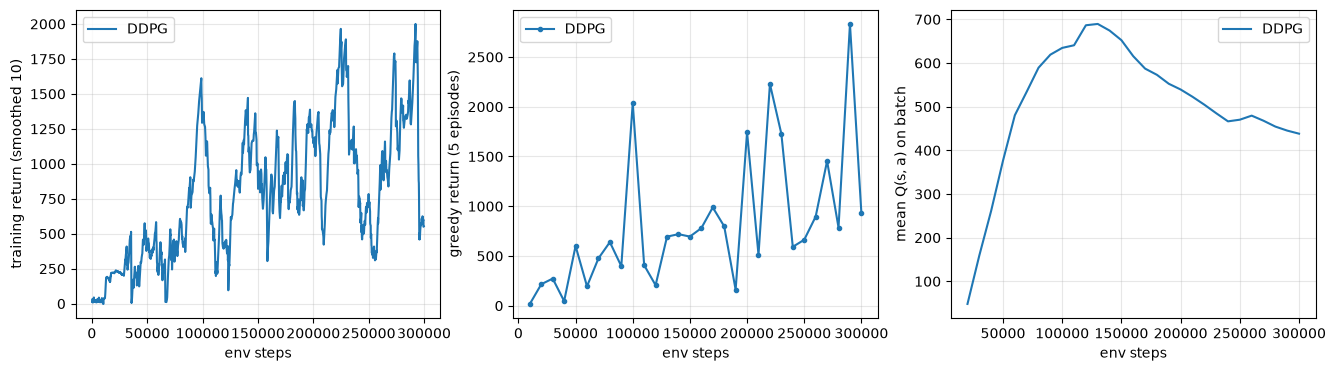

In [141]:
import matplotlib.pyplot as plt


def smooth(xs, k=10):
    return np.convolve(xs, np.ones(k) / k, mode="valid")


def plot_runs(runs, k=10):
    """runs: {label: train() result}. Training return, greedy eval return, and the critic's mean Q, vs env steps."""
    fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(16, 4))
    for label, res in runs.items():
        ax1.plot(res["ends"][k - 1 :], smooth(res["returns"], k), label=label)
        ev = res["evals"]
        ax2.plot([e["step"] for e in ev], [e["mean"] for e in ev], marker=".", label=label)
        lg = [l for l in res["log"] if "q" in l]
        ax3.plot([l["step"] for l in lg], [l["q"] for l in lg], label=label)
    ax1.set_ylabel(f"training return (smoothed {k})")
    ax2.set_ylabel("greedy return (5 episodes)")
    ax3.set_ylabel("mean Q(s, a) on batch")
    for ax in (ax1, ax2, ax3):
        ax.set_xlabel("env steps")
        ax.grid(alpha=0.3)
        ax.legend()
    plt.show()


plot_runs({"DDPG": res_ddpg})

**DDPG learns, then keeps losing it.** The greedy return reaches 2036 at 100k steps, then 407 ten thousand steps later. It does the same at 220k (2229 → 592) and at 290k (2832 → 929). That rise and collapse is the classic DDPG failure on Hopper, which Pendulum was too easy to show.

**Its Q looks too high.** Mean Q peaks near 690. With `γ = 0.99`, Q is roughly 100 × the average reward per step, so 690 means the critic expects about 6.9 reward per step forever. Even its best policy (2832 over at most 1000 steps) earns under 3 per step. Step 5 checks this directly.


## Step 4: TD3 and SAC on the same budget

Same loop, same 300k steps, same seed. On Pendulum all three tied. The question here is whether TD3's twin critics and SAC's entropy bonus fix DDPG's rise-and-collapse.


In [142]:
res_td3 = train("TD3")

steps   10000  episodes   428  train avg10=    19  greedy=    18 ±    0  
steps   20000  episodes   618  train avg10=   178  greedy=   175 ±    3  critic_loss=3.40  q=18.42
steps   30000  episodes   726  train avg10=   216  greedy=   221 ±    5  critic_loss=9.88  q=55.04
steps   40000  episodes   816  train avg10=   267  greedy=   292 ±    5  critic_loss=16.23  q=81.50
steps   50000  episodes   902  train avg10=   303  greedy=   323 ±    4  critic_loss=20.70  q=99.49
steps   60000  episodes   980  train avg10=   323  greedy=   415 ±   22  critic_loss=22.61  q=110.59
steps   70000  episodes  1035  train avg10=   597  greedy=   487 ±   12  critic_loss=26.20  q=124.29
steps   80000  episodes  1097  train avg10=   487  greedy=   473 ±   32  critic_loss=29.18  q=139.46
steps   90000  episodes  1152  train avg10=   622  greedy=   652 ±    8  critic_loss=28.74  q=148.32
steps  100000  episodes  1201  train avg10=   651  greedy=   789 ±   22  critic_loss=30.30  q=158.14
steps  110000  episodes

In [143]:
res_sac = train("SAC")

steps   10000  episodes   428  train avg10=    19  greedy=    54 ±    2  
steps   20000  episodes   539  train avg10=   231  greedy=   261 ±    9  critic_loss=12.75  q=45.15  alpha=0.16  entropy=-1.96
steps   30000  episodes   619  train avg10=   283  greedy=   313 ±    3  critic_loss=27.09  q=112.16  alpha=0.10  entropy=-2.99
steps   40000  episodes   657  train avg10=   321  greedy=   296 ±    1  critic_loss=22.34  q=131.81  alpha=0.10  entropy=-3.00
steps   50000  episodes   718  train avg10=   313  greedy=   326 ±    5  critic_loss=17.81  q=139.66  alpha=0.07  entropy=-2.99
steps   60000  episodes   777  train avg10=   494  greedy=   422 ±   12  critic_loss=21.36  q=136.65  alpha=0.06  entropy=-3.00
steps   70000  episodes   840  train avg10=   463  greedy=   450 ±    6  critic_loss=18.59  q=132.91  alpha=0.04  entropy=-2.99
steps   80000  episodes   898  train avg10=   407  greedy=   358 ±    1  critic_loss=15.59  q=131.43  alpha=0.04  entropy=-3.00
steps   90000  episodes   961  

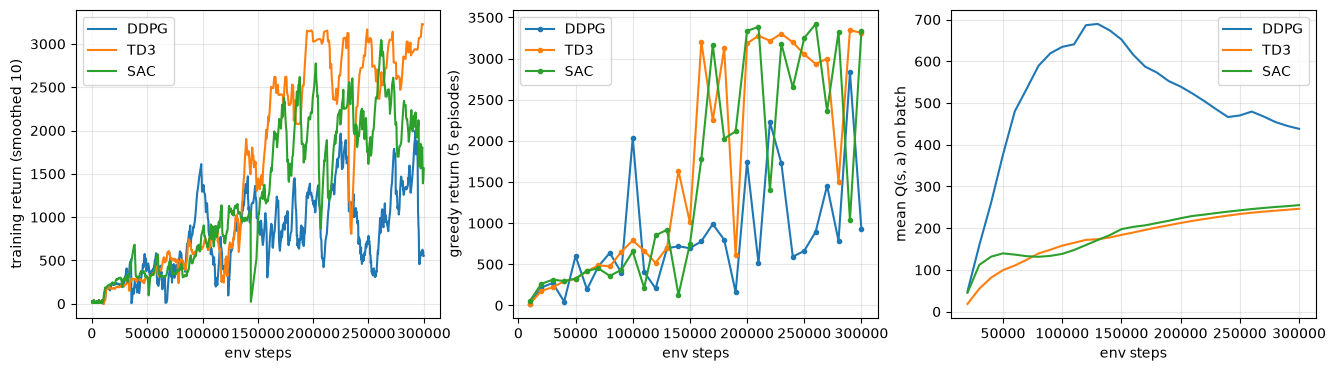

DDPG  final greedy   926 ±   95   best eval  2832   mean of last 5 evals  1380
TD3   final greedy  3310 ±   19   best eval  3346   mean of last 5 evals  2819
SAC   final greedy  3334 ±    7   best eval  3422   mean of last 5 evals  2695


In [144]:
runs = {"DDPG": res_ddpg, "TD3": res_td3, "SAC": res_sac}
plot_runs(runs)
for name, res in runs.items():
    ev = [e["mean"] for e in res["evals"]]
    m, sd = evaluate(res["agent"], n_episodes=10)
    print(
        f"{name:5s} final greedy {m:5.0f} ± {sd:4.0f}   best eval {max(ev):5.0f}   mean of last 5 evals {np.mean(ev[-5:]):5.0f}"
    )

**TD3 and SAC fix it.** Both reach about 3300 and finish there (3310 and 3334, with a spread of under 20 across 10 eval episodes). DDPG ends at 926. Look at the Q panel: DDPG's Q shoots up to about 690 and then sinks, while TD3's and SAC's rise slowly and smoothly to about 250. That is the twin-critic min at work.

**Neither is perfectly stable.** TD3 dips to 608 at 190k and to 1500 at 280k, and SAC dips to 128 at 140k and to 1036 at 290k. Both recover within one evaluation, while DDPG's collapses last. One seed only, so treat the exact numbers loosely.

**SAC's training return sits far below its greedy return** (about 1500–2700 vs 3300). Training samples from the stochastic policy, and on Hopper a little randomness is enough to tip the robot over. The greedy (mean) action is what it actually learned. Its entropy stayed pinned on the -3 target the whole run, while `α` settled near 0.06.


## Step 5: is the critic honest?

Same check as on Pendulum: run the greedy policy, compute the discounted return `G_t` it actually collects from each state, and compare with the critic's `Q(s_t, a_t)`.

The cutoff rule differs from Pendulum. An episode that **falls** has a true end, so every step's `G_t` is exact. One that reaches the **1000-step cut** loses its tail, so only the first 500 steps count. Their missing future starts at least 500 steps later, and `0.99^500 < 0.01` of it matters.

SAC is left out: its critic learns the _soft_ Q, which also counts future entropy bonuses, so it isn't comparable with `G`.


In [145]:
def q_bias(agent, n_episodes=5, gamma=0.99, horizon=500, seed=200):
    """Critic's Q(s_t, a_t) vs the discounted return actually received from s_t, on greedy episodes."""
    env = gym.make(ENV)
    qs, Gs = [], []
    for i in range(n_episodes):
        s, _ = env.reset(seed=seed + i)
        S, A, R, done = [], [], [], False
        while not done:
            a = agent.act(s, explore=False)
            S.append(s)
            A.append(a)
            s, r, term, trunc, _ = env.step(a)
            R.append(r)
            done = term or trunc
        G, ret = 0.0, []
        for r in reversed(R):
            G = r + gamma * G
            ret.append(G)
        keep = len(R) if term else horizon  # a fall is a true end: every G_t is exact
        Gs += list(reversed(ret))[:keep]
        with torch.no_grad():
            f = lambda x: torch.as_tensor(np.array(x[:keep]), dtype=torch.float32, device=device)
            qs += agent.critic(f(S), f(A)).tolist()
    return np.mean(qs), np.mean(Gs)


for name in ["DDPG", "TD3"]:
    q, g = q_bias(runs[name]["agent"])
    print(
        f"{name:5s} critic Q = {q:6.1f}   actual G = {g:6.1f}   bias = {q - g:+6.1f}  ({(q - g) / g:+.0%})"
    )

DDPG  critic Q =  463.8   actual G =  256.3   bias = +207.6  (+81%)
TD3   critic Q =  298.1   actual G =  335.8   bias =  -37.7  (-11%)


**DDPG's critic overestimates by about 80%**: it predicts 464 where the policy actually earns 256. On Pendulum the bias was only +10, which was harmless. Here it is big enough that the actor chases value that isn't there, and the policy collapses.

**TD3's critic slightly underestimates** (-11%). Taking the min of two critics errs on the pessimistic side, which is the trade TD3 makes on purpose: a critic that's a bit too low only slows learning, while one that's too high gets exploited by the actor.
